# The stellar graveyard: how heavy are the black holes and neutron stars that collide?

**CS85 astronomy teaser, project 18. Thursday prototype.**

When two black holes or neutron stars spiral into each other and merge, they shake space-time itself. The LIGO, Virgo and KAGRA detectors pick up those ripples, called **gravitational waves**. From the shape of each signal, scientists work out how heavy the two objects were, how fast they were spinning and how far away they were.

**Question:** How heavy are the objects that collide across the universe, and are there masses nature seems to avoid?

This notebook uses the public catalog of gravitational-wave detections (the *Gravitational-Wave Transient Catalog*, GWTC, through GWTC-5.0) to make:

1. Primary vs. secondary mass for every merger, colored by distance
2. Mass histograms, with the two predicted "mass gaps" marked
3. How the catalog grew from 2015 to 2025
4. Final mass vs. distance
5. *Stretch goal:* spin, and the mergers that sit inside the "pair-instability" mass gap

Every figure is also saved as a PNG in `plots/`.
**Data:** Gravitational Wave Open Science Center (GWOSC), https://gwosc.org. The full citation is at the end.

## 0. Setup

Load the libraries and find the project folders. `data/` holds downloads (it is not committed to git) and `plots/` holds the saved figures.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
import requests
from astropy.time import Time

# Find the top folder of the repo, whether the notebook runs from notebooks/ or from the top folder
ROOT = Path.cwd() if (Path.cwd() / 'plots').exists() else Path.cwd().parent
DATA = ROOT / 'data'
PLOTS = ROOT / 'plots'
DATA.mkdir(exist_ok=True)
PLOTS.mkdir(exist_ok=True)

pd.set_option('display.precision', 2)

In [2]:
# One quiet, consistent style for every figure
BLUE, ORANGE = '#2a78d6', '#eb6834'                 # colours for data
INK, INK2, MUTED = '#0b0b0b', '#52514e', '#898781'   # text colours: main, secondary, faint
GRID, AXIS, SURFACE = '#e1e0d9', '#c3c2b7', '#fcfcfb'
SHADE = '#eeede8'                                    # light gray band for "mass gaps" and observing runs
ERRBAR = '#d4d3cc'                                   # light gray for error bars

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'xtick.color': AXIS, 'ytick.color': AXIS, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'legend.frameon': False, 'figure.dpi': 100, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
})

# Colour scales.
# Distance is "how much", so it gets ONE hue going light (near) to dark (far).
DIST_CMAP = mcolors.LinearSegmentedColormap.from_list('distance', ['#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
# Spin can be negative or positive, so it gets blue (negative) <-> gray (zero) <-> red (positive).
SPIN_CMAP = mcolors.LinearSegmentedColormap.from_list('spin', ['#104281', '#3987e5', '#b4b3ac', '#e34948', '#9e2a2a'])

def plain_log_ticks(axis, ticks):
    # Show log-axis ticks as ordinary numbers (2, 5, 10, 50) instead of powers of ten
    axis.set_major_locator(mticker.FixedLocator(ticks))
    axis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:g}'))
    axis.set_minor_locator(mticker.NullLocator())

## 1. Download the catalog

GWOSC's "event API" serves the whole cumulative catalog as one small CSV file (about 100 kB), one row per detection. We save it in `data/` so it is only downloaded once.

Each number in the table is the **median** (middle) estimate. The matching `_lower` and `_upper` columns give the 90% uncertainty range, written as offsets from the median. For example, a mass of `35` with lower `-4` and upper `+6` means "probably between 31 and 41".

In [3]:
def download_once(url, filename):
    # Download a file into data/ the first time. After that, just reuse the saved copy.
    path = DATA / filename
    if not path.exists():
        response = requests.get(url, timeout=60)
        response.raise_for_status()   # stop with a clear error if the download failed
        path.write_bytes(response.content)
        print('Downloaded', url)
    return path

catalog_file = download_once('https://gwosc.org/eventapi/csv/GWTC/', 'gwtc_cumulative.csv')
df = pd.read_csv(catalog_file)
print(len(df), 'events in the catalog. Which catalog release each one comes from:')
df['catalog.shortName'].value_counts()

391 events in the catalog. Which catalog release each one comes from:


catalog.shortName
GWTC-5.0              161
GWTC-4.1              140
GWTC-2.1-confident     54
GWTC-3-confident       35
GWTC-1-confident        1
Name: count, dtype: int64

**The columns we use**

| column | what it means |
|---|---|
| `mass_1_source` | mass of the **heavier** object (the "primary"), in solar masses (M☉; 1 M☉ = the mass of the Sun) |
| `mass_2_source` | mass of the **lighter** object (the "secondary") |
| `final_mass_source` | mass of the single black hole left after the merger |
| `luminosity_distance` | distance in megaparsecs (1 Mpc ≈ 3.26 million light-years) |
| `chi_eff` | "effective spin": how much the two spins line up with the orbit (+1 = spinning fast *with* the orbit, 0 = not spinning or tilted sideways, −1 = spinning *against* it) |
| `GPS` | time of the detection, in GPS seconds (seconds since 6 January 1980) |
| `p_astro` | probability that the signal is a real astrophysical event, not detector noise |
| `far` | false-alarm rate: how often (per year) noise alone would fake a signal this convincing |

"_source" means the mass as it was in the source's own galaxy. The universe's expansion stretches the waves on their way to us, which would otherwise make faraway objects look heavier than they are.

Next we turn the GPS times into calendar dates and check which events have published masses.

In [4]:
def gps_to_date(gps):
    # Convert GPS seconds into ordinary calendar dates (UTC) using astropy
    return pd.to_datetime(Time(np.asarray(gps, dtype=float), format='gps').to_datetime())

df['date'] = gps_to_date(df['GPS'])
df['has_masses'] = df['mass_1_source'].notna()

print(df['has_masses'].sum(), 'events have published masses;', (~df['has_masses']).sum(), 'do not.')
print('First detection:', df['date'].min().date(), '   Latest detection in the catalog:', df['date'].max().date())

# How do the two groups compare? (median of each column)
comparison = df.groupby('has_masses')[['p_astro', 'far', 'network_matched_filter_snr']].median()
comparison.index = comparison.index.map({True: 'has masses', False: 'no masses'})
comparison.columns = ['chance it is real (p_astro)', 'false alarms per year (far)', 'signal-to-noise']
comparison

282 events have published masses; 109 do not.
First detection: 2015-09-14    Latest detection in the catalog: 2025-01-20


,chance it is real (p_astro),false alarms per year (far),signal-to-noise
has_masses,,,
no masses,0.71,3.90e+00,8.5
has masses,0.99,5.20e-05,11.0


**Why do 109 events have no masses?** All of them are from the two newest releases (GWTC-4.1 and GWTC-5.0), and they are the *less certain* candidates. Their typical chance of being real is about 70%, and noise would fake a signal like theirs a few times per year. For the events with masses, the chance of being real is about 99%, and noise would fake one roughly once in 20,000 years. LIGO lists the weaker candidates but hasn't published full mass estimates for them, so from here on we use only the 282 events that have masses.

Note: the catalog was *published* through 2026, but its newest detection is from **January 2025**. Later detections haven't appeared in a catalog yet.

In [5]:
events = df[df['has_masses']].copy()

def event(name):
    # Look up one event's row by its catalog name, e.g. event('GW150914')
    return events.loc[events['commonName'] == name].iloc[0]

def label(ax, name, text, text_at, x='mass_1_source', y='mass_2_source', ha='left'):
    # Write a short label at position text_at (in the plot's own units), with a thin line to the event.
    # x and y say which columns the plot uses for its axes.
    row = event(name)
    ax.annotate(text, xy=(row[x], row[y]), xytext=text_at, ha=ha, va='center', fontsize=9, color=INK2,
                arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.8, shrinkA=2, shrinkB=4,
                                relpos=(0, 0.5) if ha == 'left' else (1, 0.5)))

print(len(events), 'events with masses')

282 events with masses


## 2. Who's in the graveyard? Primary vs. secondary mass

Each dot is one merger: the heavier object's mass across, the lighter one's mass up. Because m₁ is always the heavier one, every dot falls below the diagonal line of equal masses.

A neutron star can't be heavier than about 2 to 3 M☉; any heavier and it collapses into a black hole. So the dashed lines at **3 M☉** roughly split the plot into neutron-star pairs, black hole + neutron star pairs, and black-hole pairs.

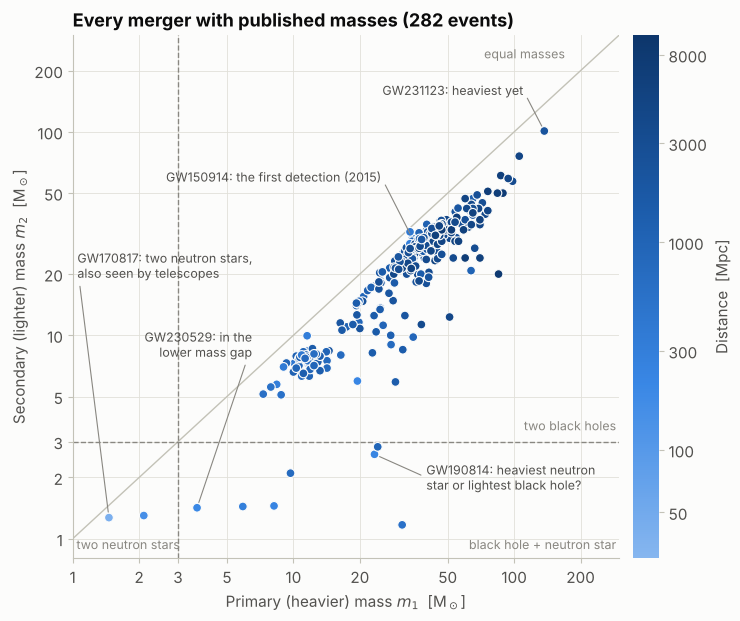

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 6.8))

ax.plot([1, 300], [1, 300], color=AXIS, lw=1, zorder=1)                     # equal-mass line
ax.text(170, 230, 'equal masses', color=MUTED, fontsize=9, ha='right')
for line in (ax.axvline, ax.axhline):                                        # neutron star / black hole divide
    line(3, color=MUTED, lw=1, ls='--', zorder=1)

dots = ax.scatter(events['mass_1_source'], events['mass_2_source'], c=events['luminosity_distance'],
                  cmap=DIST_CMAP, norm=mcolors.LogNorm(vmin=30, vmax=10000),
                  s=40, edgecolors=SURFACE, linewidths=0.8, zorder=3)

# Name the three regions
ax.text(1.04, 0.86, 'two neutron stars', fontsize=9, color=MUTED, va='bottom')
ax.text(290, 0.86, 'black hole + neutron star', fontsize=9, color=MUTED, ha='right', va='bottom')
ax.text(290, 3.3, 'two black holes', fontsize=9, color=MUTED, ha='right', va='bottom')

# Label a few famous events. The empty space above the diagonal is a good place for the text.
label(ax, 'GW150914', 'GW150914: the first detection (2015)', (25, 60), ha='right')
label(ax, 'GW231123_135430', 'GW231123: heaviest yet', (110, 160), ha='right')
label(ax, 'GW170817', 'GW170817: two neutron stars,\nalso seen by telescopes', (1.05, 22))
label(ax, 'GW230529_181500', 'GW230529: in the\nlower mass gap', (6.5, 9), ha='right')
label(ax, 'GW190814', 'GW190814: heaviest neutron\nstar or lightest black hole?', (40, 2.0))

ax.set(xscale='log', yscale='log', xlim=(1, 300), ylim=(0.8, 300),
       xlabel='Primary (heavier) mass $m_1$  [M$_\\odot$]', ylabel='Secondary (lighter) mass $m_2$  [M$_\\odot$]')
plain_log_ticks(ax.xaxis, [1, 2, 3, 5, 10, 20, 50, 100, 200])
plain_log_ticks(ax.yaxis, [1, 2, 3, 5, 10, 20, 50, 100, 200])
ax.set_title(f'Every merger with published masses ({len(events)} events)')

bar = fig.colorbar(dots, ax=ax, pad=0.02)
bar.set_label('Distance  [Mpc]', color=INK2)
plain_log_ticks(bar.ax.yaxis, [50, 100, 300, 1000, 3000, 8000])
bar.outline.set_visible(False)

fig.savefig(PLOTS / '18_masses_colored_by_distance.png')
plt.show()

**What this shows.** Almost all of the 282 mergers are pairs of black holes, mostly between about 5 and 100 M☉, and the two partners usually have similar masses (the dots hug the diagonal). The dark blue (faraway) dots are almost all in the upper right: heavier mergers make louder waves, so we can hear them from farther away. Only nine dots sit below the 3 M☉ line. Those are collisions involving a neutron star (or something just as light), and they are all relatively nearby, within about 1,000 Mpc (lighter blue). Neutron stars are small, so their mergers are quiet.

## 3. Mass histograms: which masses are common, and which are missing?

A histogram counts how many events fall in each mass range. The bins are evenly spaced on a *logarithmic* scale, so the small neutron stars and the 100 M☉ black holes both show up clearly.

Two ranges are shaded in gray. Astronomers have long suspected nature makes few objects with these masses:

- **Lower mass gap, about 3–5 M☉:** between the heaviest neutron stars and the lightest black holes seen in our own galaxy.
- **Pair-instability gap, about 50–130 M☉:** stars that would make black holes this heavy are expected to blow themselves apart completely instead (more on this in section 6).

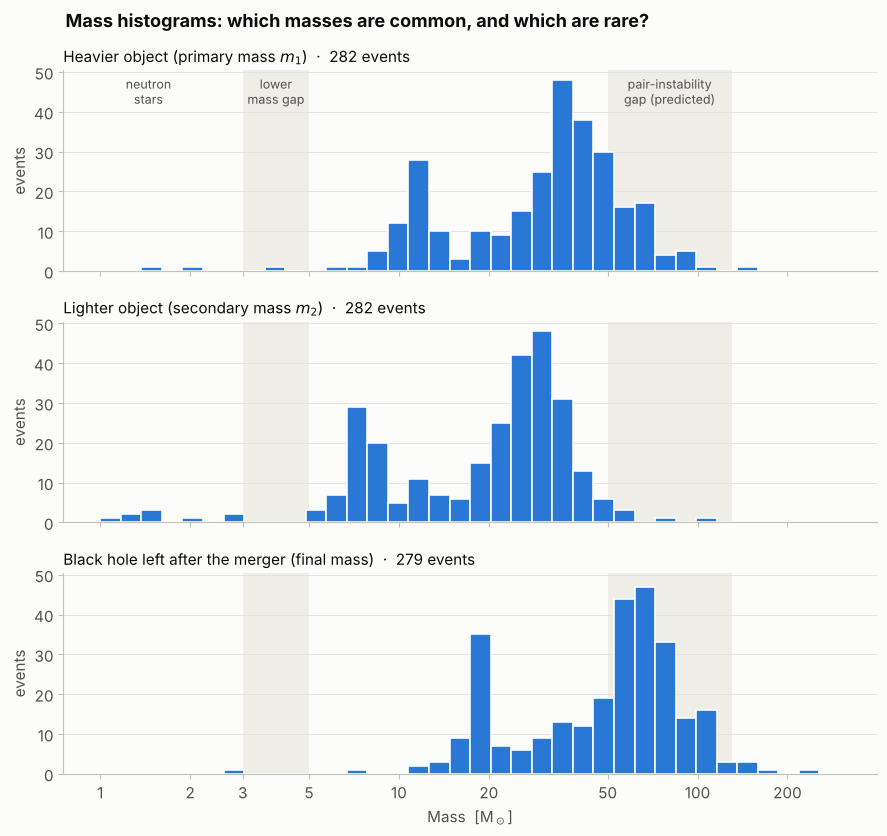

In [7]:
bins = np.logspace(0, np.log10(300), 37)   # 36 bins from 1 to 300 Msun, evenly spaced on a log scale
panels = [('mass_1_source', 'Heavier object (primary mass $m_1$)'),
          ('mass_2_source', 'Lighter object (secondary mass $m_2$)'),
          ('final_mass_source', 'Black hole left after the merger (final mass)')]

fig, axes = plt.subplots(3, 1, figsize=(9, 8.5), sharex=True, sharey=True)
for ax, (column, title) in zip(axes, panels):
    values = events[column].dropna()
    ax.axvspan(3, 5, color=SHADE, lw=0, zorder=0)
    ax.axvspan(50, 130, color=SHADE, lw=0, zorder=0)
    ax.hist(values, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=2)
    ax.set_title(f'{title}  ·  {len(values)} events', fontsize=11, fontweight='normal', color=INK)
    ax.set_ylabel('events')
    ax.grid(axis='x', visible=False)

# Name the shaded ranges once, on the top panel
top = axes[0]
ymax = top.get_ylim()[1]
top.text(np.sqrt(3 * 5), ymax * 0.97, 'lower\nmass gap', ha='center', va='top', fontsize=9, color=INK2)
top.text(np.sqrt(50 * 130), ymax * 0.97, 'pair-instability\ngap (predicted)', ha='center', va='top', fontsize=9, color=INK2)
top.text(1.45, ymax * 0.97, 'neutron\nstars', ha='center', va='top', fontsize=9, color=INK2)

axes[-1].set_xscale('log')
plain_log_ticks(axes[-1].xaxis, [1, 2, 3, 5, 10, 20, 50, 100, 200])
axes[-1].set_xlabel('Mass  [M$_\\odot$]')
fig.suptitle('Mass histograms: which masses are common, and which are rare?', x=0.08, ha='left',
             fontsize=13, fontweight='bold', color=INK)
fig.tight_layout()

fig.savefig(PLOTS / '18_mass_histograms.png')
plt.show()

Here are the same numbers as a table: how many objects fall in each mass range (using each event's median mass).

In [8]:
ranges = [0, 3, 5, 50, 130, 1000]
range_names = ['below 3 (neutron stars)', '3–5 (lower gap)', '5–50', '50–130 (pair-instability gap)', 'above 130']
counts = pd.DataFrame({
    'primary m1': pd.cut(events['mass_1_source'], ranges, labels=range_names).value_counts(sort=False),
    'secondary m2': pd.cut(events['mass_2_source'], ranges, labels=range_names).value_counts(sort=False),
    'final mass': pd.cut(events['final_mass_source'], ranges, labels=range_names).value_counts(sort=False),
})
counts.index.name = 'mass range [Msun]'
counts

,primary m1,secondary m2,final mass
mass range [Msun],,,
below 3 (neutron stars),2,9,1
3–5 (lower gap),1,0,0
5–50,226,267,109
50–130 (pair-instability gap),52,6,163
above 130,1,0,6


**What this shows.**
- **Two crowded spots:** many black holes are around **10 M☉**, and there is a second bump around **30–35 M☉**. These are the most common black-hole masses that merge.
- **The lower gap really is sparse.** Very few objects sit between 3 and 5 M☉. The most notable is GW230529, whose heavier object (about 3.7 M☉) falls right in the gap.
- **The pair-instability gap is *not* empty.** 52 primary black holes have median masses between 50 and 130 M☉, and so do 163 of the 279 final black holes. That's expected for final masses, since two 30 M☉ black holes merge into a ~57 M☉ one, but it's a puzzle for black holes that supposedly formed from a single star.
- **Caution:** these are histograms of *detected* events, and heavy mergers are louder, so they're over-represented compared with the real universe. Each event's mass is also uncertain (see section 6).

## 4. How the catalog grew, 2015 → 2025

The detectors don't run all the time. They observe in **observing runs** (O1, O2, O3, O4) with long breaks in between for upgrades. GWOSC publishes the start and end of each run, so we download those too.

In [9]:
runs_file = download_once('https://gwosc.org/api/v2/runs', 'gwosc_runs.json')
runs = pd.DataFrame(json.loads(runs_file.read_text())['results'])
runs = runs[runs['name'].isin(['O1', 'O2', 'O3a', 'O3b', 'O4a', 'O4b'])].reset_index(drop=True)
runs['start'] = gps_to_date(runs['gps_start'])
runs['end'] = gps_to_date(runs['gps_end'])
runs[['name', 'start', 'end', 'detectors']]

,name,start,end,detectors
0,O1,2015-09-12 00:00:36,2016-01-19 16:00:36,"[H1, L1]"
1,O2,2016-11-30 16:00:36,2017-08-25 22:00:37,"[H1, L1, V1]"
2,O3a,2019-04-01 15:00:37,2019-10-01 15:00:37,"[H1, L1, V1]"
3,O3b,2019-11-01 15:00:37,2020-03-27 17:00:37,"[H1, L1, V1]"
4,O4a,2023-05-15 14:13:59,2024-01-16 16:00:37,"[H1, L1]"
5,O4b,2024-04-06 05:37:49,2025-01-28 17:00:37,"[H1, L1, V1]"


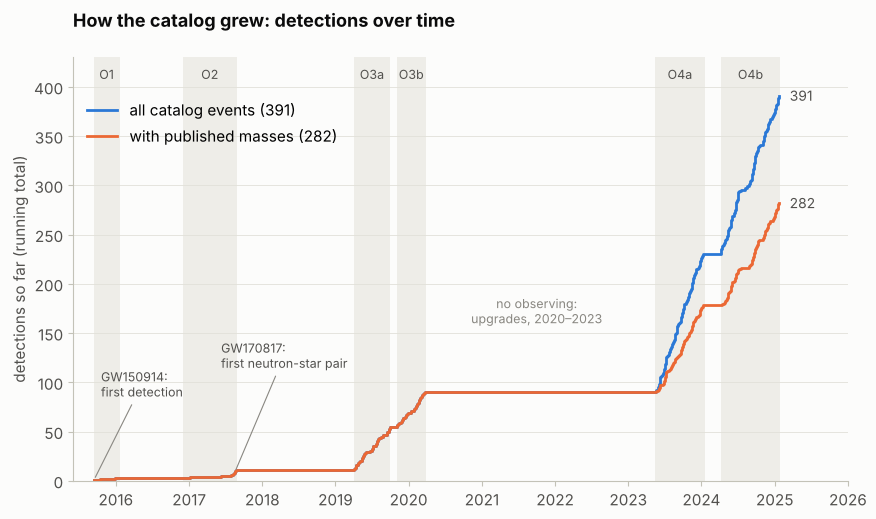

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.5))

for _, run in runs.iterrows():                      # gray band = detectors observing
    ax.axvspan(run['start'], run['end'], color=SHADE, lw=0, zorder=0)
    middle = run['start'] + (run['end'] - run['start']) / 2
    ax.text(middle, 405, run['name'], ha='center', va='bottom', fontsize=9, color=INK2)

series = [(df, BLUE, 'all catalog events'), (events, ORANGE, 'with published masses')]
for subset, colour, name in series:
    dates = subset['date'].sort_values()
    running_total = np.arange(1, len(dates) + 1)
    ax.step(dates, running_total, where='post', color=colour, lw=2, label=f'{name} ({len(dates)})', zorder=3)
    ax.annotate(f'{len(dates)}', xy=(dates.iloc[-1], running_total[-1]), xytext=(8, 0),   # number at line end
                textcoords='offset points', va='center', fontsize=10, color=INK2)

ax.annotate('GW150914:\nfirst detection', xy=(event('GW150914')['date'], 1), xytext=(5, 60),
            textcoords='offset points', fontsize=9, color=INK2,
            arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.8))
gw170817_date = event('GW170817')['date']
ax.annotate('GW170817:\nfirst neutron-star pair', xy=(gw170817_date, (df['date'] <= gw170817_date).sum()), xytext=(-10, 75),
            textcoords='offset points', fontsize=9, color=INK2,
            arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.8))
ax.text(pd.Timestamp('2021-10-01'), 160, 'no observing:\nupgrades, 2020–2023', ha='center', fontsize=9, color=MUTED)

ax.set(xlim=(pd.Timestamp('2015-06-01'), pd.Timestamp('2026-01-01')), ylim=(0, 430),
       ylabel='detections so far (running total)')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left', bbox_to_anchor=(0, 0.93))
ax.set_title('How the catalog grew: detections over time', pad=22)

fig.savefig(PLOTS / '18_catalog_growth.png')
plt.show()

In [11]:
# How many events per observing run, and how fast they arrived
runs['days long'] = (runs['gps_end'] - runs['gps_start']) / 86400
runs['events'] = [df['GPS'].between(a, b).sum() for a, b in zip(runs['gps_start'], runs['gps_end'])]
runs['events per week'] = runs['events'] / (runs['days long'] / 7)
runs[['name', 'start', 'days long', 'events', 'events per week']].round(1)

,name,start,days long,events,events per week
0,O1,2015-09-12 00:00:36,129.7,3,0.2
1,O2,2016-11-30 16:00:36,268.3,8,0.2
2,O3a,2019-04-01 15:00:37,183.0,44,1.7
3,O3b,2019-11-01 15:00:37,147.1,35,1.7
4,O4a,2023-05-15 14:13:59,246.1,140,4.0
5,O4b,2024-04-06 05:37:49,297.5,161,3.8


**What this shows.** The total grows in steps: it climbs during each observing run (gray bands) and stays flat during the breaks, when the detectors were being upgraded. Each upgrade made the detectors more sensitive, so they could hear mergers from farther away, and the detection rate went from about one event every 6 weeks in 2015 to about **four per week** in O4. More than three quarters of all detections (301 of 391) come from the most recent run, O4. The gap between the two lines is the 109 less-certain candidates without masses.

## 5. Final mass vs. distance

After two objects merge, a single black hole is left. Its **final mass** is a little less than the two masses added together, because a few percent of the mass is radiated away as gravitational-wave energy (E = mc²). Gray lines show each event's 90% uncertainty range.

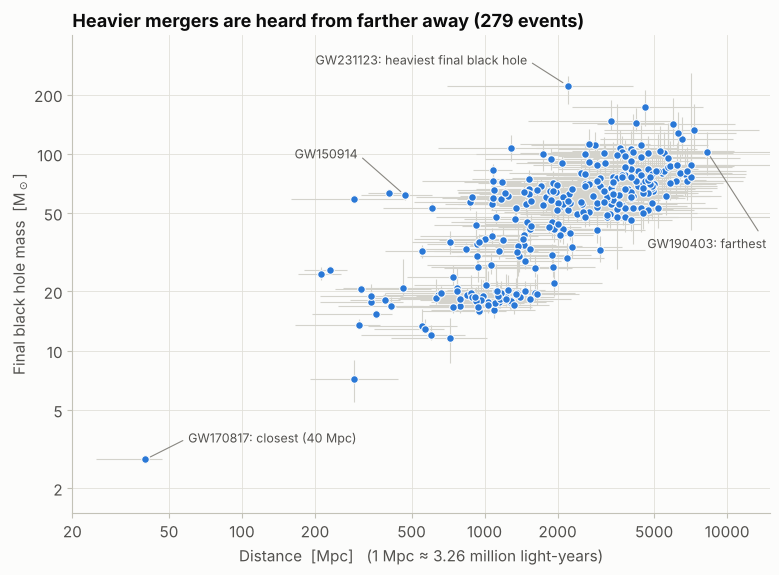

In [12]:
fm = events.dropna(subset=['final_mass_source'])
x, y = fm['luminosity_distance'], fm['final_mass_source']
x_err = [-fm['luminosity_distance_lower'], fm['luminosity_distance_upper']]
y_err = [-fm['final_mass_source_lower'].fillna(0), fm['final_mass_source_upper'].fillna(0)]

fig, ax = plt.subplots(figsize=(9, 6.2))
ax.errorbar(x, y, xerr=x_err, yerr=y_err, fmt='none', ecolor=ERRBAR, elinewidth=0.8, zorder=1)
ax.scatter(x, y, s=30, color=BLUE, edgecolors=SURFACE, linewidths=0.8, zorder=3)

farthest = fm.loc[fm['luminosity_distance'].idxmax(), 'commonName']
along = dict(x='luminosity_distance', y='final_mass_source')    # this plot's axes
label(ax, 'GW170817', 'GW170817: closest (40 Mpc)', (60, 3.6), **along)
label(ax, 'GW150914', 'GW150914', (300, 100), ha='right', **along)
label(ax, 'GW231123_135430', 'GW231123: heaviest final black hole', (1500, 300), ha='right', **along)
label(ax, farthest, f'{farthest[:8]}: farthest', (14500, 35), ha='right', **along)

ax.set(xscale='log', yscale='log', xlim=(20, 15000), ylim=(1.5, 400),
       xlabel='Distance  [Mpc]   (1 Mpc ≈ 3.26 million light-years)', ylabel='Final black hole mass  [M$_\\odot$]')
plain_log_ticks(ax.xaxis, [20, 50, 100, 200, 500, 1000, 2000, 5000, 10000])
plain_log_ticks(ax.yaxis, [2, 5, 10, 20, 50, 100, 200])
ax.set_title(f'Heavier mergers are heard from farther away ({len(fm)} events)')

fig.savefig(PLOTS / '18_final_mass_vs_distance.png')
plt.show()

In [13]:
# Median final mass of the nearest, middle and farthest thirds of the events
thirds = pd.qcut(fm['luminosity_distance'], 3, labels=['nearest third', 'middle third', 'farthest third'])
fm.groupby(thirds, observed=True).agg(
    events=('commonName', 'count'),
    distance_range_Mpc=('luminosity_distance', lambda d: f'{d.min():.0f}–{d.max():.0f}'),
    median_final_mass=('final_mass_source', 'median'))

,events,distance_range_Mpc,median_final_mass
luminosity_distance,,,
nearest third,93,40–1450,20.2
middle third,93,1460–3310,57.7
farthest third,93,3320–8280,74.0


**What this shows.** The dots form a rising band: the nearest third of events have a median final mass of about 20 M☉, while the farthest third are about 74 M☉, more than three times heavier. This doesn't mean black holes used to be heavier. It's a **selection effect**: heavy mergers are louder, so the detectors can pick them up from much farther away, while small ones are only heard when they're close. The neutron-star merger GW170817 (final mass about 2.8 M☉) could only be detected because it was very nearby. Distances are also more uncertain than masses (the long horizontal gray lines).

## 6. Stretch goal: spin, and the pair-instability gap

**Why there should be a gap.** In the extremely hot core of a very massive star, light gets so energetic that it turns into pairs of electrons and positrons. That drains the pressure holding the core up, so the core collapses and ignites a runaway thermonuclear explosion. In the heaviest stars this blows the whole star apart, leaving **no black hole at all**; somewhat lighter ones throw off much of their mass in bursts first. As a result, theory predicts no black holes *made directly from a star* between about **50 and 130 M☉** (the edges are uncertain by maybe 10–20 M☉).

**So what are the black holes we find there?** One idea is that they are "second-generation" black holes, built from an *earlier* merger, perhaps in a crowded star cluster where black holes keep running into each other. A black hole made by a merger is left spinning quite fast, and in a crowded cluster its spin could point in any direction. So we'd expect gap black holes to show a **wider range of spins** than ordinary ones.

Below: the masses again (on ordinary, non-log axes), now colored by effective spin. Gray lines show the 90% range for the 19 events whose heavier black hole is very likely in the gap (its whole 90% range lies above 50 M☉).

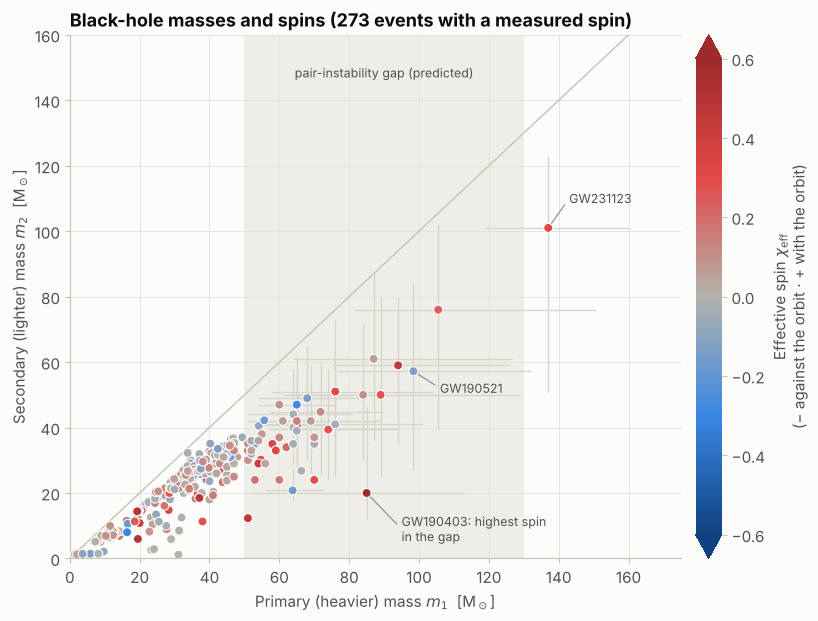

In [14]:
GAP_LOW, GAP_HIGH = 50, 130
spin = events.dropna(subset=['chi_eff']).copy()
m1_low_end = spin['mass_1_source'] + spin['mass_1_source_lower']    # bottom of the 90% range for m1
spin['m1_in_gap'] = m1_low_end > GAP_LOW
gap = spin[spin['m1_in_gap']]

fig, ax = plt.subplots(figsize=(9.5, 6.8))
ax.axvspan(GAP_LOW, GAP_HIGH, color=SHADE, lw=0, zorder=0)
ax.text(np.mean([GAP_LOW, GAP_HIGH]), 147, 'pair-instability gap (predicted)', ha='center', fontsize=9, color=INK2)
ax.plot([0, 200], [0, 200], color=AXIS, lw=1, zorder=1)

ax.errorbar(gap['mass_1_source'], gap['mass_2_source'],
            xerr=[-gap['mass_1_source_lower'], gap['mass_1_source_upper']],
            yerr=[-gap['mass_2_source_lower'], gap['mass_2_source_upper']],
            fmt='none', ecolor=ERRBAR, elinewidth=0.9, zorder=1)
dots = ax.scatter(spin['mass_1_source'], spin['mass_2_source'], c=spin['chi_eff'],
                  cmap=SPIN_CMAP, norm=mcolors.Normalize(vmin=-0.6, vmax=0.6),
                  s=42, edgecolors=SURFACE, linewidths=0.8, zorder=3)

label(ax, 'GW231123_135430', 'GW231123', (143, 110))
label(ax, 'GW190521', 'GW190521', (106, 52))
label(ax, 'GW190403_051519', 'GW190403: highest spin\nin the gap', (95, 9))

ax.set(xlim=(0, 175), ylim=(0, 160),
       xlabel='Primary (heavier) mass $m_1$  [M$_\\odot$]', ylabel='Secondary (lighter) mass $m_2$  [M$_\\odot$]')
ax.set_title(f'Black-hole masses and spins ({len(spin)} events with a measured spin)')

bar = fig.colorbar(dots, ax=ax, pad=0.02, extend='both')
bar.set_label('Effective spin $\\chi_{\\rm eff}$\n(− against the orbit · + with the orbit)', color=INK2)
bar.outline.set_visible(False)

fig.savefig(PLOTS / '18_spin_and_pair_instability_gap.png')
plt.show()

**The 19 events whose heavier black hole is very likely in the gap.** Each value is shown as "median (90% range)".

In [15]:
def with_range(row, column, digits=0):
    # Format a value as "median (low–high)" using its 90% range
    mid, low, high = row[column], row[column] + row[column + '_lower'], row[column] + row[column + '_upper']
    return f'{mid:.{digits}f} ({low:.{digits}f}–{high:.{digits}f})'

gap_table = pd.DataFrame({
    'event': gap['commonName'],
    'catalog': gap['catalog.shortName'],
    'm1 [Msun]': gap.apply(with_range, axis=1, column='mass_1_source'),
    'm2 [Msun]': gap.apply(with_range, axis=1, column='mass_2_source'),
    'final mass [Msun]': gap.apply(with_range, axis=1, column='final_mass_source'),
    'effective spin': gap.apply(with_range, axis=1, column='chi_eff', digits=2),
    'distance [Mpc]': gap['luminosity_distance'].round(-1).astype(int),
}).sort_values('m1 [Msun]', key=lambda s: s.str.split().str[0].astype(float), ascending=False)
gap_table.reset_index(drop=True)

,event,catalog,m1 [Msun],m2 [Msun],final mass [Msun],effective spin,distance [Mpc]
0,GW231123_135430,GWTC-4.1,137 (119–160),101 (51–123),222 (180–250),0.32 (-0.09–0.57),2200
1,GW190426_190642,GWTC-2.1-confident,106 (81–151),76 (40–102),173 (139–211),0.23 (-0.18–0.65),4580
2,GW190521,GWTC-2.1-confident,98 (77–132),57 (27–84),147 (131–187),-0.14 (-0.59–0.36),3310
3,GW231028_153006,GWTC-4.1,94 (75–126),59 (35–80),144 (131–171),0.45 (0.26–0.61),4200
4,GW230704_212616,GWTC-4.1,89 (62–129),50 (25–80),132 (101–179),0.27 (-0.16–0.62),7300
5,GW200220_061928,GWTC-3-confident,87 (64–127),61 (36–87),141 (110–192),0.06 (-0.32–0.46),6000
6,GW190403_051519,GWTC-2.1-confident,85 (52–113),20 (12–46),102 (78–128),0.68 (0.25–0.84),8280
7,GW231005_021030,GWTC-4.1,84 (61–113),50 (30–72),127 (102–163),0.10 (-0.27–0.46),6300
8,GW231001_140220,GWTC-4.1,76 (54–101),41 (25–59),111 (89–140),-0.04 (-0.39–0.29),4400
9,GW230922_040658,GWTC-4.1,76 (58–104),51 (27–73),119 (98–153),0.31 (0.00–0.57),6500


In [16]:
# Do the gap black holes spin differently from the rest?
groups = spin['m1_in_gap'].map({True: 'm1 very likely in the gap', False: 'all other events'})
spin.groupby(groups)['chi_eff'].agg(
    events='count',
    median_spin='median',
    spread_of_spins='std',
    share_with_spin_above_0_2=lambda s: (s > 0.2).mean())

,events,median_spin,spread_of_spins,share_with_spin_above_0_2
m1_in_gap,,,,
all other events,254,0.05,0.12,0.10
m1 very likely in the gap,19,0.12,0.24,0.42


**What this shows.**
- **The gap has residents.** 19 mergers have a heavier black hole very likely between 50 and 130 M☉, including GW231123 (about 137 M☉, the heaviest so far) and GW190521. Their error bars are wide, but for these 19 even the low end of the 90% range is above 50 M☉.
- **Their spins look a bit different.** Most black holes in the catalog have effective spins close to zero (the grayish dots). For the 19 gap events, the spread of spins is about twice as wide, and 42% have an effective spin above 0.2, compared with 10% of all other events. That fits, at least loosely, with the "second-generation black hole" idea, but with only 19 events and large spin uncertainties it's a hint, not proof.
- **Caveats:** the gap's lower edge could really be closer to 60–70 M☉, which would empty some of these out. Heavy black holes give very short signals, so their spins are measured less precisely. And effective spin mixes two spins and their directions into one number, so a value near zero doesn't mean the black holes weren't spinning.

## 7. Things to say honestly at the demo

- **Medians hide uncertainty.** Every mass, spin and distance has a range, often ±20% or more. The histograms use only the middle value.
- **Detected is not the same as typical.** Heavy, nearby mergers are easiest to hear, so the catalog over-represents them. Real population studies correct for the detectors' sensitivity, and we haven't.
- **The newest data is incomplete.** 109 less certain candidates have no masses yet, and nothing after January 2025 is in the catalog.
- **Numbers can change.** Each new catalog version re-analyzes some events, so values can shift slightly between releases.

## 8. Ideas for next steps

- Make the first plot **interactive** with plotly, so hovering over a dot shows the event's name and numbers.
- Add the error bars to the histograms by drawing each event as a spread-out bump instead of a single point.
- Pick one gap event (GW231123 or GW190521) and pair it with project 19: download its strain data and *listen* to it.

## Data source and citation

- **Catalog:** LIGO Scientific Collaboration, Virgo Collaboration and KAGRA Collaboration, *Gravitational-Wave Transient Catalog* (cumulative, GWTC-1 through GWTC-5.0), from the Gravitational Wave Open Science Center event API: https://gwosc.org/eventapi/csv/GWTC/ (event pages: https://gwosc.org/eventapi/html/GWTC/).
- **Observing-run dates:** GWOSC API, https://gwosc.org/api/v2/runs
- **License:** GWOSC data are released under the Creative Commons Attribution 4.0 International (CC BY 4.0) license.
- **References GWOSC asks users to cite** (https://gwosc.org/acknowledgement/):
  - LIGO Scientific Collaboration, Virgo Collaboration, KAGRA Collaboration, "Open Data from LIGO, Virgo, and KAGRA through the Second Part of the Fourth Observing Run", arXiv:2605.27090
  - LIGO Scientific Collaboration, Virgo Collaboration, KAGRA Collaboration, "Open Data from LIGO, Virgo, and KAGRA through the First Part of the Fourth Observing Run", ApJ 1004, 2329 (2026)
  - R. Abbott et al., "Open data from the third observing run of LIGO, Virgo, KAGRA and GEO", ApJS 267, 29 (2023)
  - R. Abbott et al., "Open data from the first and second observing runs of Advanced LIGO and Advanced Virgo", SoftwareX 13, 100658 (2021)
- **Acknowledgment (GWOSC's requested wording):** "This research has made use of data or software obtained from the Gravitational Wave Open Science Center (gwosc.org), a service of the LIGO Scientific Collaboration, the Virgo Collaboration, and KAGRA. This material is based upon work supported by NSF's LIGO Laboratory which is a major facility fully funded by the National Science Foundation, as well as the Science and Technology Facilities Council (STFC) of the United Kingdom, the Max-Planck-Society (MPS), and the State of Niedersachsen/Germany for support of the construction of Advanced LIGO and construction and operation of the GEO600 detector. Additional support for Advanced LIGO was provided by the Australian Research Council. Virgo is funded, through the European Gravitational Observatory (EGO), by the French Centre National de Recherche Scientifique (CNRS), the Italian Istituto Nazionale di Fisica Nucleare (INFN) and the Dutch Nikhef, with contributions by institutions from Belgium, Germany, Greece, Hungary, Ireland, Japan, Monaco, Poland, Portugal, Spain. KAGRA is supported by Ministry of Education, Culture, Sports, Science and Technology (MEXT), Japan Society for the Promotion of Science (JSPS) in Japan; National Research Foundation (NRF) and Ministry of Science and ICT (MSIT) in Korea; Academia Sinica (AS) and National Science and Technology Council (NSTC) in Taiwan.\"

In [17]:
# When the catalog file in data/ was downloaded (useful for the citation)
import datetime
print('Catalog file downloaded on', datetime.date.fromtimestamp(catalog_file.stat().st_mtime))

Catalog file downloaded on 2026-11-10
